## MEC568 Artemis Launch Mission Project

Joseph Litjens <br>
Nick Zhang <br>
Steven Chen

In [1652]:
##IMPORT LIBRARIES

import numpy as np
import matplotlib.pyplot as plt
import scipy as sp

In [1653]:
## Environmental constants definition

u_earth = 398600.4418*10**9 #m^3/s^2, gravitational constant | GM_e
u_moon = 4902.800*10**9 #m^3/s^2, gravitational constant | GM_m
r_earth = 6378.137*1000 #m, earth equatorial radius
r_moon = 1737.4*1000 #m, mean moon rad
d_EM = 384400*1000 #m, mean distance from earth center to moon center
n_mean = 2.6653 * (10**(-6)) #rad/s, "mean motion" | Angular velocity of the Moon around the Earth
mr_CR3 = 0.012151 #mass ratio, ul | M_m / (M_e + M_m)
lu_CR3 = 384400*1000 #length unit for CR3BP
tu_CR3 = 4.342*24*60*60 #seconds, time unit for CR3BP
vu_CR3 = 1.0245*1000 #m/s, velocity unit for CR3BP
g0 = 9.80665 #m/s, standard gravity constant

In [1654]:
## DEFINE INITIAL CONDITIONS AND SPACECRAFT PARAMETERS (TASK 2)

N = 20000 #number of runge kutta steps (dt = [t_end - t_start]/N)
r0 = np.array([(r_earth + 185000),0 , 0]) #in m | at low Earth orbit
v0 = np.array([0, np.sqrt(u_earth/np.linalg.norm(r0)), 0]) #in m | v = sqrt(GM_e/r)
m0 = 1000 #in kg | initial mass of the spacecraft
Isp = 316 #s, specific impulse (placeholder, Orion ESM main engine; update to your engine)
theta0 = 2.18 #rad, moon phase angle at t=0 (tuned so the moon is where the spacecraft arrives)
state0 = np.concatenate([r0, v0, [m0]]) #state vector (r, v, m) | initial state of the spacecraft

In [1655]:
## Helper Functions

def get_moon_pos(t): #get moon position at time t from t=0
    moon_pos = d_EM * np.array([np.cos(n_mean*t + theta0), np.sin(n_mean*t + theta0), 0]).T # expressed in componets
    return moon_pos

def get_accel_ECI(current_pos, current_T, current_moon_pos, current_m):
    sc_accel_ECI = -(u_earth/((np.linalg.norm(current_pos))**3)) * current_pos - u_moon*((current_pos - current_moon_pos)/((np.linalg.norm(current_pos - current_moon_pos))**3) + (current_moon_pos)/((np.linalg.norm(current_moon_pos))**3)) + current_T / current_m
    return sc_accel_ECI # from the equation

def state_diff(t, state, T, Isp): #differentiate the state vector wrt time (r,v,m) -> (v,a,mdot)
    r = state[0:3] #spacecraft position vector
    v = state[3:6] #spacecraft velocity vector
    m = state[6] #spacecraft mass
    a = get_accel_ECI(r, T, get_moon_pos(t), m) #get the current acceleration
    mdot = np.linalg.norm(T)/(Isp*g0) #propellant mass flow rate (positive), zero when T = 0
    return np.concatenate([v, a, [-mdot]]) #return differentiated current state

def eci_to_rot(pos_eci, t): #convert ECI position to Earth-Moon rotating frame
    current_ang = n_mean*t + theta0 #angle of the Earth-Moon line from the ECI x-axis 
    #perform rotation (note this is essentially just multiplication by rotation matrix)
    x = np.cos(current_ang) * pos_eci[0] + np.sin(current_ang) * pos_eci[1] 
    y = -np.sin(current_ang) * pos_eci[0] + np.cos(current_ang) * pos_eci[1]
    z = pos_eci[2] #z pos is unchanged in the plane as the problem was defined
    x = x - mr_CR3*d_EM #shift origin from Earth's center to the barycenter
    return np.array([x, y, z])


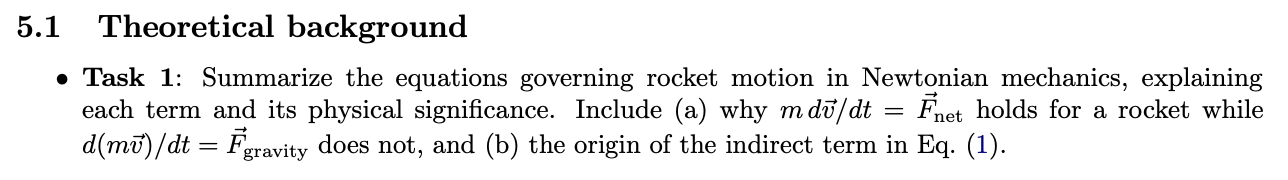

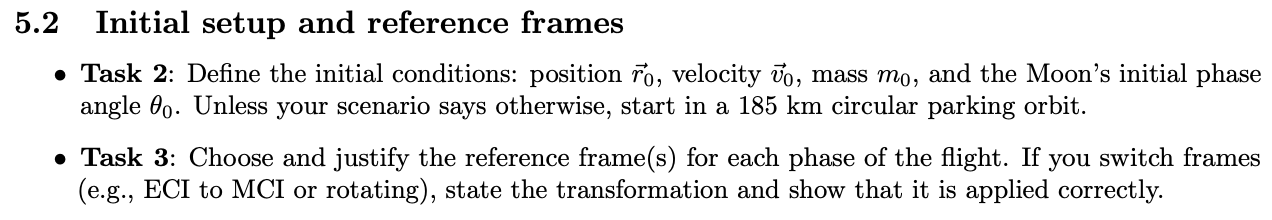

## Explanation of reference frame

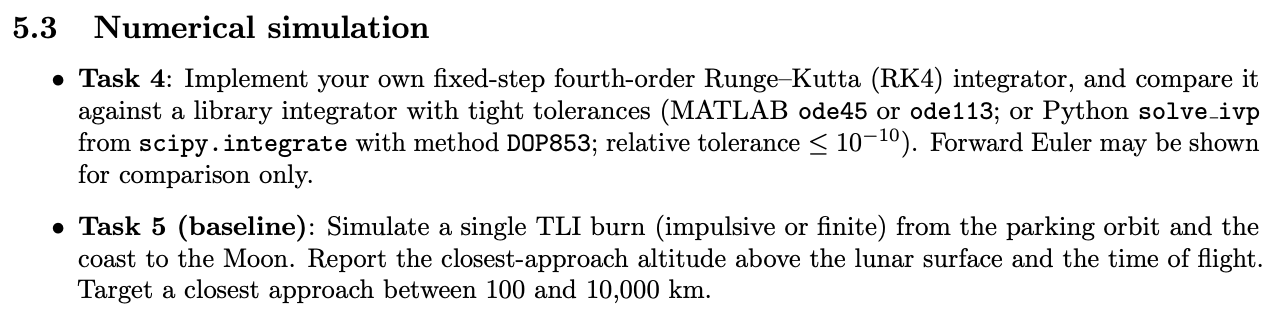<br>
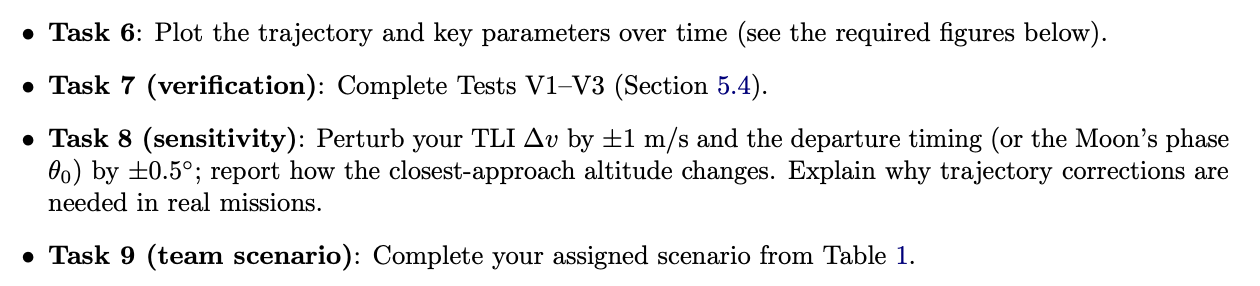

In [1656]:
## Task 4: RK4 integrator function and solve_ivp comparison

def rk4(state, T, Isp, t, dt): #RK4 implementation
    #for more info on algorithm read https://lpsa.swarthmore.edu/NumInt/NumIntFourth.html
    k1 = state_diff(t, state, T, Isp) #k1 is simply the euler method result
    k2 = state_diff(t + dt/2, state + dt/2*k1, T, Isp) #perform euler method again after a dt/2 timestep forward
    k3 = state_diff(t + dt/2, state + dt/2*k2, T, Isp) #perform euler AGAIN after a dt/2 timestep but using k2
    k4 = state_diff(t + dt, state + dt*k3, T, Isp) #perform again using k3 for a dt forward timestep
    new_state = state + dt/6*(k1 + 2*k2 + 2*k3 + k4) #add the estimated state change to the current state to find next state
    return new_state

def run_sim(state0, T, Isp, t_start, t_end, N):
    #propagate state0 from t_start to t_end with BOTH our custom rk4 and scipy's solve_ivp, returns time vector, and solution arrays
    dt = (t_end - t_start)/N #fixed timestep, found from the number of steps
    t = t_start + dt*np.arange(N+1) #time array; take start time and add an array with timesteps from index 0 to N+1

    #custom rk4 (fixed step)
    state_rk4 = np.zeros((N+1, 7)) #each row is (x, y, z, vx, vy, vz, m); initialize the state matrix
    state_rk4[0] = state0
    for i in range(N): #perform RK4 iterations
        state_rk4[i+1] = rk4(state_rk4[i], T, Isp, t[i], dt)

    #scipy solution for reference (DOP853, tight tolerance)
    #args are (state derivative function, time span/domain, initial conditions, extra args used in state_diff, solver method, time vector, relative tolerance)
    sol = sp.integrate.solve_ivp(state_diff, (t[0], t[-1]), state0, args=(T, Isp), method='DOP853', t_eval=t, rtol=1e-10) #create solution object
    state_scipy = sol.y.T #gather the state array, and transpose it to match format of the custom rk4 solver output

    return t, state_rk4, state_scipy

In [1657]:
## Task 5: TLI Burn

dv_TLI = 3145 #m/s, impulsive TLI (instantaneous change in velocity), section 4.5 said 3100 baseline, but we tuned via trial-and-error to meet spec
t_end = 178.5*3600 #s, coasting for a number of hours

T_off = np.zeros(3) #no thrust during the coast

m_prop = m0*(1 - np.exp(-dv_TLI/(Isp*g0))) #propellant used, from the rocket equation

#impulsive burn: instantly add delta v along the velocity direction of the parking orbit, and remove the propellant mass
state_TLI = np.concatenate([r0, v0 + dv_TLI*v0/np.linalg.norm(v0), [m0 - m_prop]]) #same position, faster velocity, less mass

#propagate with both integrators
t, state_rk4, state_scipy = run_sim(state_TLI, T_off, Isp, 0, t_end, N) # giving it an initial boost, no thrust afterward.

#altitude above the lunar surface vs time, for each integrator
moon_pos_t = np.array([get_moon_pos(tt) for tt in t]) #moon position at every time step
moon_dist_rk4 = np.linalg.norm(state_rk4[:, 0:3] - moon_pos_t, axis=1) - r_moon #distance from moon surface to spacecraft (aka altitude) in RK4
moon_dist_scipy = np.linalg.norm(state_scipy[:, 0:3] - moon_pos_t, axis=1) - r_moon #distance from moon surface to spacecraft (aka altitude) in SciPy

#closest approach = minimum altitude
min_alt_rk4 = np.argmin(moon_dist_rk4) #find minimum value for RK4 altitude
min_alt_scipy = np.argmin(moon_dist_scipy) #find min value for scipy altitude

print(f"RK4: closest approach altitude = {moon_dist_rk4[min_alt_rk4]/1000:.3f} km, time of flight = {t[min_alt_rk4]/3600:.3f} h")
print(f"scipy: closest approach altitude = {moon_dist_scipy[min_alt_scipy]/1000:.3f} km, time of flight = {t[min_alt_scipy]/3600:.3f} h")
print(f"Difference in closest approach altitude = {abs(moon_dist_rk4[min_alt_rk4] - moon_dist_scipy[min_alt_scipy]):.3f} m")
print(f"TLI delta v (impulsive) = {dv_TLI} m/s, propellant used = {m_prop:.1f} kg")

RK4: closest approach altitude = 6406.012 km, time of flight = 88.197 h
scipy: closest approach altitude = 6406.210 km, time of flight = 88.197 h
Difference in closest approach altitude = 197.677 m
TLI delta v (impulsive) = 3145 m/s, propellant used = 637.6 kg


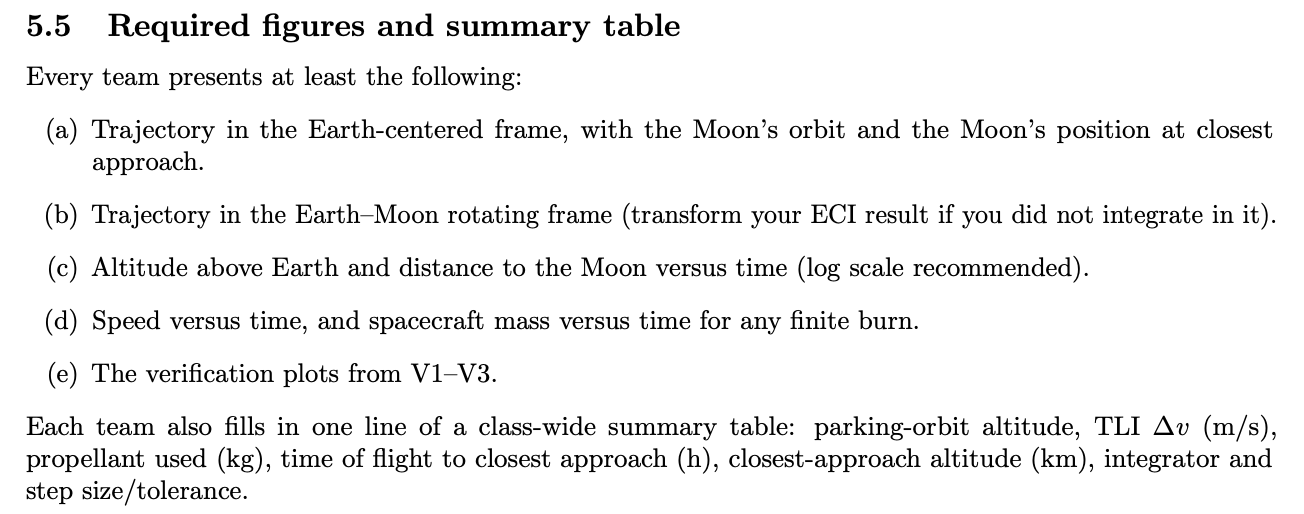

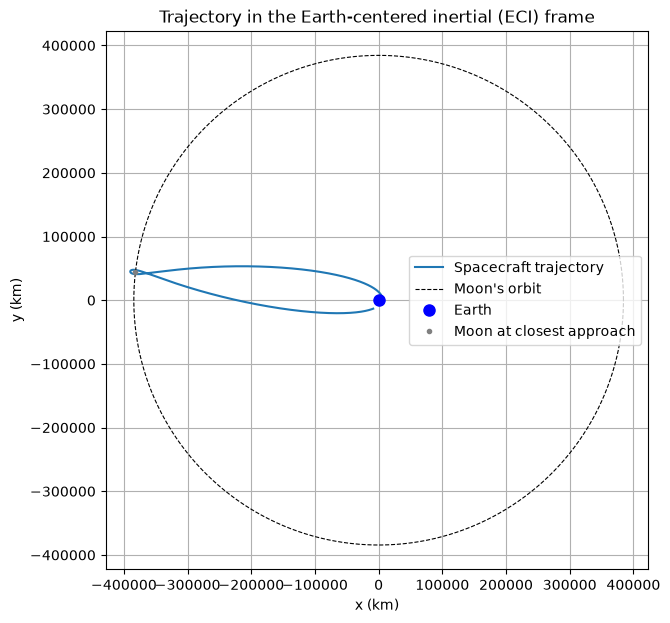

In [1658]:
## Task 6A: Trajectory in the Earth-centered frame

fig, ax = plt.subplots(figsize=(7, 7))

ax.plot(state_rk4[:, 0]/1000, state_rk4[:, 1]/1000, label='Spacecraft trajectory') #spacecraft path in ECI for x and y coordinates, converted to km

ang = np.linspace(0, 2*np.pi, 400) # discretized angles
ax.plot(d_EM/1000*np.cos(ang), d_EM/1000*np.sin(ang), 'k--', linewidth=0.8, label="Moon's orbit") #moon's circular orbit

ax.plot(0, 0, 'o', label='Earth', color='blue', markersize=8) #earth at the origin

moon_close_pos = moon_pos_t[min_alt_rk4] #moon position at the time of closest approach
ax.plot(moon_close_pos[0]/1000, moon_close_pos[1]/1000, 'o', color='gray', markersize=3, label='Moon at closest approach')

ax.set_aspect('equal') #equal axis scaling so the moon orbit appears circular
ax.set_xlabel('x (km)')
ax.set_ylabel('y (km)')
ax.set_title('Trajectory in the Earth-centered inertial (ECI) frame')
ax.legend()
ax.grid(True)
plt.show()

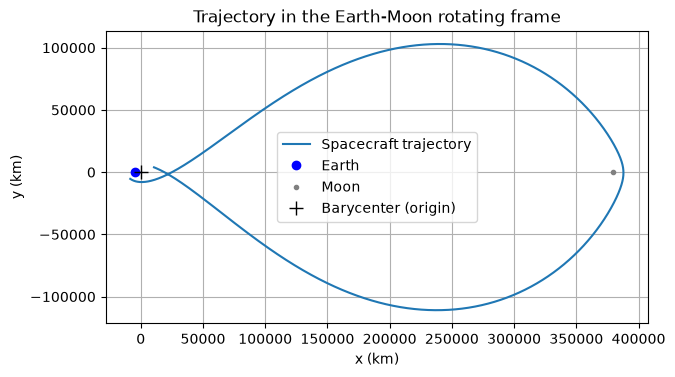

In [1659]:
## Task 6B: Trajectory in the Earth-Moon rotating frame

#transform every point of the ECI trajectory into the rotating frame
traj_rot = np.array([eci_to_rot(state_rk4[i, 0:3], t[i]) for i in range(len(t))]) # converting the x position to the Earth-Moon rotating frame

fig, ax = plt.subplots(figsize=(7, 7))

ax.plot(traj_rot[:, 0]/1000, traj_rot[:, 1]/1000, label='Spacecraft trajectory') #spacecraft path in the rotating frame, converted to km

ax.plot(eci_to_rot(np.zeros(3), 0)[0]/1000, 0, 'o',  color='blue', markersize=6, label='Earth') #earth (origin of ECI) sits just left of the barycenter
ax.plot(eci_to_rot(moon_pos_t[0], t[0])[0]/1000, 0, 'o', color='gray', markersize=3, label='Moon') #the moon is fixed in this frame
ax.plot(0, 0, 'k+', markersize=10, label='Barycenter (origin)')

ax.set_aspect('equal') #equal axis scaling
ax.set_xlabel('x (km)')
ax.set_ylabel('y (km)')
ax.set_title('Trajectory in the Earth-Moon rotating frame')
ax.legend()
ax.grid(True)
plt.show()

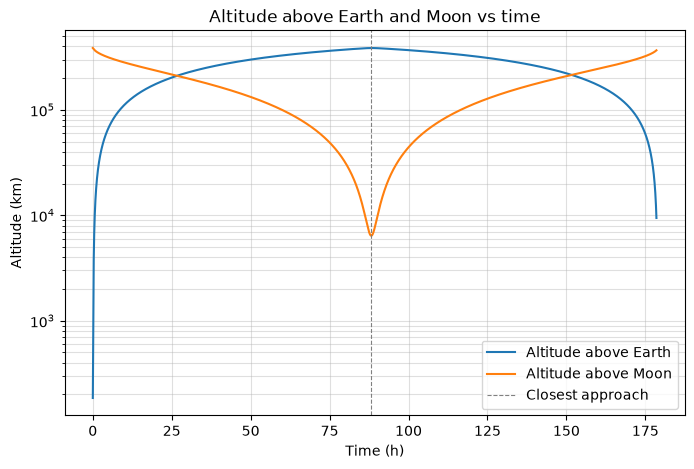

In [1660]:
## Task 6C: Altitude above Earth and distance to the Moon vs time

alt_earth = np.linalg.norm(state_rk4[:, 0:3], axis=1) - r_earth #altitude above earth's surface at every time step

fig, ax = plt.subplots(figsize=(8, 5))

ax.semilogy(t/3600, alt_earth/1000, label='Altitude above Earth') #log scale on the y axis, time in hours, altitude in km
ax.semilogy(t/3600, moon_dist_rk4/1000, label='Altitude above Moon')

ax.axvline(t[min_alt_rk4]/3600, color='gray', linestyle='--', linewidth=0.8, label='Closest approach') #mark the time of closest approach

ax.set_xlabel('Time (h)')
ax.set_ylabel('Altitude (km)')
ax.set_title('Altitude above Earth and Moon vs time')
ax.legend()
ax.grid(True, which='both', alpha=0.4)
plt.show()

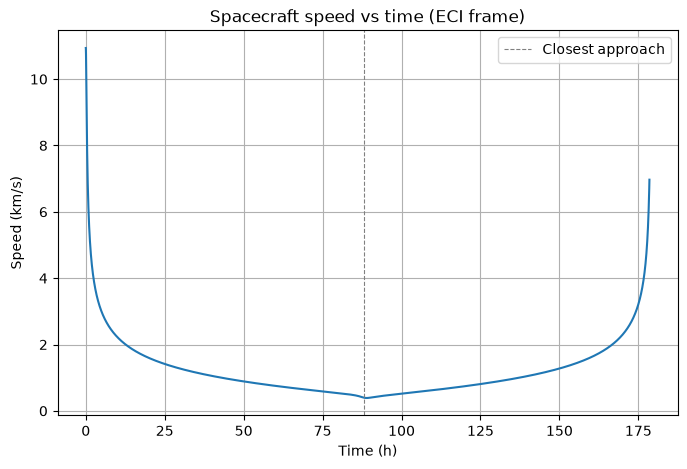

In [1661]:
## Task 6D: Speed vs time

speed = np.linalg.norm(state_rk4[:, 3:6], axis=1) #spacecraft speed at every time step (magnitude of ECI velocity)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(t/3600, speed/1000) #time in hours, speed in km/s
ax.axvline(t[min_alt_rk4]/3600, color='gray', linestyle='--', linewidth=0.8, label='Closest approach') #mark the time of closest approach

ax.set_xlabel('Time (h)')
ax.set_ylabel('Speed (km/s)')
ax.set_title('Spacecraft speed vs time (ECI frame)')
ax.legend()
ax.grid(True)
plt.show()

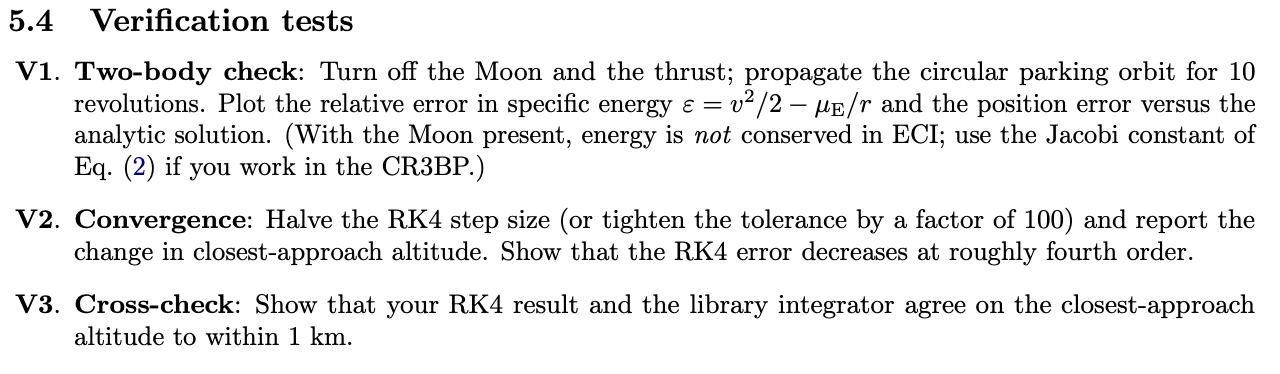

max relative/percent energy error: RK4 = 5.47e-08, scipy = 2.27e-08
max position error after 10 revolutions: RK4 = 4.048e-01 m, scipy = 5.456e-03 m


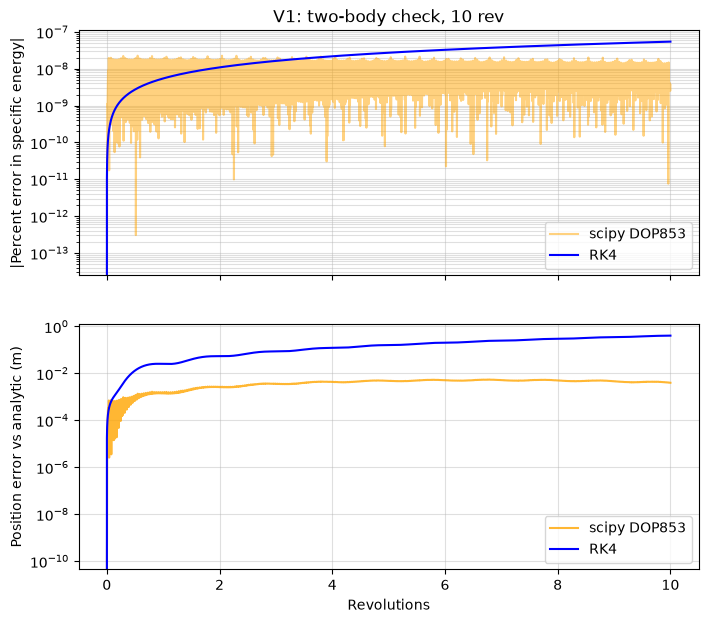

In [1694]:
## Task 7 V1: Two-body check w/o moon and thrust

r_park = np.linalg.norm(r0) #parking orbit radius
T_orb = 2*np.pi*np.sqrt(r_park**3/u_earth) #period of the circular parking orbit from Kepler's 3rd law
t_end_V1 = 10*T_orb #time to achieve 10 revolutions
n_V1 = 5000 #total rk4 steps for V1 test (500 per revolution)
T_zero = np.zeros(3) #no thrust throughout the test

#turn the moon off by setting u_moon = 0 (essentially saying there is no gravity from the moon)
u_moon_saved = u_moon #store the old value so we can use it later
u_moon = 0
t_V1, state_rk4_V1, state_scipy_V1 = run_sim(state0, T_zero, Isp, 0, t_end_V1, n_V1) #run simulation with new values
u_moon = u_moon_saved #reset to original value

#analytic solution: circular orbit starting on the +x axis, moving in +y
w = np.sqrt(u_earth/r_park**3) #orbital angular rate from Kepler's 3rd law
pos_analytical = r_park*np.array([np.cos(w*t_V1), np.sin(w*t_V1), np.zeros_like(t_V1)]).T #exact analytical position. Draws the orbit

#specific energy eps = v^2/2 - u/r at every time step
eps_rk4 = 0.5*np.linalg.norm(state_rk4_V1[:, 3:6], axis=1)**2 - u_earth/np.linalg.norm(state_rk4_V1[:, 0:3], axis=1) 
eps_scipy = 0.5*np.linalg.norm(state_scipy_V1[:, 3:6], axis=1)**2 - u_earth/np.linalg.norm(state_scipy_V1[:, 0:3], axis=1)
eps0 = eps_rk4[0] # intial specific energy, accepted as reference for relative error calculations
#relative/percent error
rel_err_eps_rk4 = 100*(eps_rk4 - eps0)/abs(eps0)
rel_err_eps_scipy = 100*(eps_scipy - eps0)/abs(eps0)

#position error vs the analytic solution
pos_err_rk4 = np.linalg.norm(state_rk4_V1[:, 0:3] - pos_analytical, axis=1)
pos_err_scipy = np.linalg.norm(state_scipy_V1[:, 0:3] - pos_analytical, axis=1)

print(f"max relative/percent energy error: RK4 = {np.max(np.abs(rel_err_eps_rk4)):.2e}, scipy = {np.max(np.abs(rel_err_eps_scipy)):.2e}")
print(f"max position error after 10 revolutions: RK4 = {np.max(pos_err_rk4):.3e} m, scipy = {np.max(pos_err_scipy):.3e} m")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 7), sharex=True)

ax1.semilogy(t_V1/T_orb, np.abs(rel_err_eps_scipy), label='scipy DOP853',color='orange', alpha=0.5)
ax1.semilogy(t_V1/T_orb, np.abs(rel_err_eps_rk4), label='RK4',color='blue', alpha=1)
ax1.set_ylabel('|Percent error in specific energy|')
ax1.set_title('V1: two-body check, 10 rev')
ax1.legend()
ax1.grid(True, which='both', alpha=0.4)

ax2.semilogy(t_V1/T_orb, pos_err_scipy, label='scipy DOP853',color='orange', alpha=0.8)
ax2.semilogy(t_V1/T_orb, pos_err_rk4, label='RK4',color='blue', alpha=1)
ax2.set_xlabel('Revolutions')
ax2.set_ylabel('Position error vs analytic (m)')
ax2.legend()
ax2.grid(True, which='both', alpha=0.4)
plt.show()

In [1695]:
## Task 7 V2 and V3: Convergence and cross-check

n_list = 5000*2**np.arange(5) #number of rk4 steps for each run: each is double the last, so each timestep is half the last
dt_V2 = t_end/n_list #timestep of each run
alt_rk4_V2 = np.zeros(len(n_list)) #closest approach altitude from rk4, for each run
alt_scipy_V2 = np.zeros(len(n_list)) #closest approach altitude from scipy, for each run

for j in range(len(n_list)): #iterate through solutiions
    t_j, state_rk4_j, state_scipy_j = run_sim(state_TLI, T_off, Isp, 0, t_end, n_list[j]) #same TLI scenario as task 5
    moon_pos_j = np.array([get_moon_pos(tt) for tt in t_j])
    alt_rk4_V2[j] = np.min(np.linalg.norm(state_rk4_j[:, 0:3] - moon_pos_j, axis=1)) - r_moon #altiutde from rk4
    alt_scipy_V2[j] = np.min(np.linalg.norm(state_scipy_j[:, 0:3] - moon_pos_j, axis=1)) - r_moon #altitude from scipy

alt_ref = alt_scipy_V2[-1] #reference closest approach altitude: scipy (rtol = 1e-10) on the finest grid.
err_V2 = np.abs(alt_rk4_V2 - alt_ref) #rk4 error vs the reference
order_V2 = np.log2(err_V2[:-1]/err_V2[1:]) #observed order: error should drop by 2^p each time the step is halved (p = 4 for rk4)

print(f"reference closest approach altitude (scipy) = {alt_ref/1000:.4f} km")
print(f"{'N':>7} {'dt (s)':>8} {'RK4 altitude (km)':>19} {'scipy altitude (km)':>20} {'change from last (m)':>21} {'error (m)':>12} {'observed order':>15}")
for j in range(len(n_list)):
    change = f"{alt_rk4_V2[j] - alt_rk4_V2[j-1]:21.3f}" if j > 0 else f"{'-':>21}"
    order = f"{order_V2[j-1]:15.2f}" if j > 0 else f"{'-':>15}"
    print(f"{n_list[j]:7d} {dt_V2[j]:8.2f} {alt_rk4_V2[j]/1000:19.4f} {alt_scipy_V2[j]/1000:20.4f} {change} {err_V2[j]:12.3f} {order}")

rel_change_V2 = np.abs(alt_rk4_V2[1:] - alt_rk4_V2[:-1])/alt_rk4_V2[:-1] #change in closest approach altitude from the previous (coarser) run, relative to that previous result

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(dt_V2[1:], rel_change_V2, 'o-', label='RK4 results') #each point is plotted at the timestep of the newer (finer) run

#best fit of the form y = c*dt^4 (fourth order curve through the origin); least squares for the one coefficient c
c_fit = np.sum(rel_change_V2*dt_V2[1:]**4)/np.sum(dt_V2[1:]**8)
dt_smooth = np.linspace(0, dt_V2[1], 200)
ax.plot(dt_smooth, c_fit*dt_smooth**4, 'k--', linewidth=0.8, label=f'fit: {c_fit:.2e} dt^4')
ax.set_xlabel('Timestep dt (s)')
ax.set_ylabel('Relative change from previous result')
ax.set_title('V2: RK4 convergence')
ax.legend()
ax.grid(True)
plt.show()

KeyboardInterrupt: 

In [ ]:
## Task 8: Sensitivity of the closest approach altitude (RK4 only)

theta0_nominal = theta0 #save the nominal moon phase angle so it can be restored
dv_offsets = np.linspace(-1, 1, 9) #m/s, perturbations to the TLI delta v
phase_offsets = np.linspace(-0.5, 0.5, 9) #degrees, perturbations to the moon phase angle theta0
dt_sens = t_end/N #same timestep as task 5
t_sens = dt_sens*np.arange(N+1) #time array shared by every run
alt_dv = np.zeros(len(dv_offsets)) #closest approach altitude for each delta v perturbation
alt_phase = np.zeros(len(phase_offsets)) #closest approach altitude for each phase perturbation

#sweep 1: vary ONLY the TLI delta v (moon phase stays nominal)
for j in range(len(dv_offsets)):
    state_hist = np.zeros((N+1, 7)) #each row is (x, y, z, vx, vy, vz, m)
    state_hist[0] = np.concatenate([r0, v0 + (dv_TLI + dv_offsets[j])*v0/np.linalg.norm(v0), [m0 - m_prop]])
    for i in range(N):
        state_hist[i+1] = rk4(state_hist[i], T_off, Isp, t_sens[i], dt_sens)
    moon_pos_j = np.array([get_moon_pos(tt) for tt in t_sens])
    alt_dv[j] = np.min(np.linalg.norm(state_hist[:, 0:3] - moon_pos_j, axis=1)) - r_moon

#sweep 2: vary ONLY the moon phase angle (delta v stays nominal)
for j in range(len(phase_offsets)):
    theta0 = theta0_nominal + np.radians(phase_offsets[j]) #get_moon_pos reads this global
    state_hist = np.zeros((N+1, 7))
    state_hist[0] = state_TLI
    for i in range(N):
        state_hist[i+1] = rk4(state_hist[i], T_off, Isp, t_sens[i], dt_sens)
    moon_pos_j = np.array([get_moon_pos(tt) for tt in t_sens])
    alt_phase[j] = np.min(np.linalg.norm(state_hist[:, 0:3] - moon_pos_j, axis=1)) - r_moon
theta0 = theta0_nominal #restore the nominal moon phase angle

#results: the middle entry of each sweep (offset = 0) is the nominal case
alt_nominal = alt_dv[len(dv_offsets)//2]
print(f"nominal closest approach altitude = {alt_nominal/1000:.3f} km\n")
print("Delta v sweep (moon phase nominal)")
print(f"{'dv offset (m/s)':>16} {'closest approach (km)':>22} {'change from nominal (km)':>26}")
for j in range(len(dv_offsets)):
    print(f"{dv_offsets[j]:16.2f} {alt_dv[j]/1000:22.3f} {(alt_dv[j] - alt_nominal)/1000:26.3f}")
print("\nMoon phase sweep (delta v nominal)")
print(f"{'phase offset (deg)':>19} {'closest approach (km)':>22} {'change from nominal (km)':>26}")
for j in range(len(phase_offsets)):
    print(f"{phase_offsets[j]:19.3f} {alt_phase[j]/1000:22.3f} {(alt_phase[j] - alt_nominal)/1000:26.3f}")

#plot 1: delta v only
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(dv_offsets, alt_dv/1000, 'o-')
ax.plot(0, alt_nominal/1000, 'ro', label='Nominal') #nominal case
ax.set_xlabel('TLI delta v offset (m/s)')
ax.set_ylabel('Closest approach altitude (km)')
ax.set_title('Sensitivity to TLI delta v (moon phase held at nominal)')
ax.legend()
ax.grid(True)
plt.show()

#plot 2: moon phase only
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(phase_offsets, alt_phase/1000, 'o-')
ax.plot(0, alt_nominal/1000, 'ro', label='Nominal') #nominal case
ax.set_xlabel('Moon phase angle offset (deg)')
ax.set_ylabel('Closest approach altitude (km)')
ax.set_title('Sensitivity to moon phase angle (delta v held at nominal)')
ax.legend()
ax.grid(True)
plt.show()

KeyboardInterrupt: 

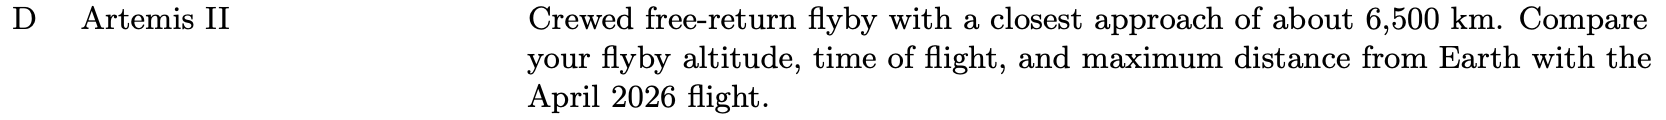

In [ ]:
## Task 9: Group-specific scenario - D


# Initial conditions during Artimis II 
theta0 = 176/180 * np.pi # moon phase during the launch of Artimis II
r0_artimis_ii = np.array([(r_earth + 185000)*np.cos(-0.8918), (r_earth + 185000)*np.sin(-0.8918) , 0]) #in m tuned so it reaches the moon

# Launch conditions for Artimis II
dv_TLI_artimis_ii = 3141.10 #m/s
t_end_artimis_ii = 179.83*3600

# Simulate the Artemis II trajectory
state_TLI_artimis_ii = np.concatenate([r0_artimis_ii, v0 + dv_TLI_artimis_ii*v0/np.linalg.norm(v0), [m0 - m_prop]]) #same position, faster velocity, less mass
t_artimis_ii, state_rk4_artimis_ii, state_scipy_artimis_ii = run_sim(state_TLI_artimis_ii, T_off, Isp, 0, t_end_artimis_ii, N) # giving it an initial boost, no thrust afterward.

moon_pos_t_artimis_ii = np.array([get_moon_pos(tt) for tt in t_artimis_ii]) #moon position at every time step for Artemis II
moon_dist_rk4_artimis_ii = np.linalg.norm(state_rk4_artimis_ii[:, 0:3] - moon_pos_t_artimis_ii, axis=1) - r_moon #distance from moon surface to spacecraft (aka altitude) in RK4
moon_dist_scipy_artimis_ii = np.linalg.norm(state_scipy_artimis_ii[:, 0:3] - moon_pos_t_artimis_ii, axis=1) - r_moon #distance from moon surface to spacecraft (aka altitude) in SciPy

#closest approach = minimum altitude
min_alt_rk4_artimis_ii = np.argmin(moon_dist_rk4_artimis_ii) #find minimum value for RK4 altitude
min_alt_scipy_artimis_ii = np.argmin(moon_dist_scipy_artimis_ii) #find min value for scipy altitude

# Results from RK4 solution
earth_dist_rk4 = np.linalg.norm(state_rk4_artimis_ii[:, 0:3], axis=1) # obtaining the distance from the Earth
max_earth_dist_rk4 = np.max(earth_dist_rk4) 
time_of_flight_rk4 = np.max(t_artimis_ii)

# Result from Scipy solution
earth_dist_scipy = np.linalg.norm(state_scipy_artimis_ii[:, 0:3], axis=1) # obtaining the distance from the Earth
max_earth_dist_scipy = np.max(earth_dist_scipy) 
time_of_flight_scipy = np.max(t_artimis_ii)

# Official Artemis II data
flyby_alt_artemis_ii_official = 6545 # example value in km
fly_time_artemis_ii_official = 9*24 + 1 + 32/60 # example value in hours
max_earth_dist_artemis_ii_official = 406740 # example maximum distance from Earth in km

#print(np.linalg.norm(state_rk4_artimis_ii[-1,0:3]) - r_earth)
print('Official Artemis II Data')
print(f"{'Close Approach Altitude (km)':>28} | {'Maximum Distance From Earth (km)':>32} | {'Time of Flight (h)':>18}")
print(f"{flyby_alt_artemis_ii_official:28.3f} | {max_earth_dist_artemis_ii_official:32.3f} | {fly_time_artemis_ii_official:18.3f}")

print()
print('Comparison of simulated results and the official Artemis II data')
print(f"{'Simulation Methods':18} | {'Close Approach Altitude (km)':>28} | {'Percent Error (%)':>19} | {'Maximum Distance From Earth (km)':>32} | {'Percent Error (%)':>19} | {'Time of Flight(h)':>25} | {'Percent Error (%)':>19}")
print(f"{'RK4':18} | {moon_dist_rk4_artimis_ii[min_alt_rk4_artimis_ii]/1000:28.3f} | {abs(moon_dist_rk4_artimis_ii[min_alt_rk4_artimis_ii]/1000 - flyby_alt_artemis_ii_official)/flyby_alt_artemis_ii_official*100:19.3f} | {max_earth_dist_rk4/1000:32.3f} | {abs(max_earth_dist_rk4/1000 - max_earth_dist_artemis_ii_official)/max_earth_dist_artemis_ii_official*100:19.3f} | {time_of_flight_rk4/3600:25.3f} | {abs(time_of_flight_rk4/3600 - fly_time_artemis_ii_official)/fly_time_artemis_ii_official*100:19.3f}")
print(f"{'Scipy':18} | {moon_dist_scipy_artimis_ii[min_alt_scipy_artimis_ii]/1000:28.3f} | {abs(moon_dist_scipy_artimis_ii[min_alt_scipy_artimis_ii]/1000 - flyby_alt_artemis_ii_official)/flyby_alt_artemis_ii_official*100:19.3f} | {max_earth_dist_scipy/1000:32.3f} | {abs(max_earth_dist_scipy/1000 - max_earth_dist_artemis_ii_official)/max_earth_dist_artemis_ii_official*100:19.3f} | {time_of_flight_scipy/3600:25.3f} | {abs(time_of_flight_scipy/3600 - fly_time_artemis_ii_official)/fly_time_artemis_ii_official*100:19.3f}")

Official Artemis II Data
Close Approach Altitude (km) | Maximum Distance From Earth (km) | Time of Flight (h)
                    6545.000 |                       406740.000 |            217.533

Comparison of simulated results and the official Artemis II data
Simulation Methods | Close Approach Altitude (km) |   Percent Error (%) | Maximum Distance From Earth (km) |   Percent Error (%) |         Time of Flight(h) |   Percent Error (%)
RK4                |                     6552.653 |               0.117 |                       392762.369 |               3.437 |                   179.830 |              17.332
Scipy              |                     6746.285 |               3.075 |                       392945.910 |               3.391 |                   179.830 |              17.332
